<div dir='rtl'>
    مقدمه :

    در ابتدا نگاهی به دیتا ست می اندازیم و مراحل پیش پردازش و نرمال سازی داده هارو انجام میدیم

    در انتها
</div>

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('Dataset.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


نگاهی کلی به دیتاها، تغییر و پیش پردازش در صورت نیاز

In [5]:
print(f'data shape is : {df.shape}')
print(df.dtypes)

data shape is : (200, 5)
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


In [6]:
df['Gender'] = df['Gender'].map({
    'Male': 0,
    'Female': 1
})
df.dtypes

CustomerID                int64
Gender                    int64
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

ایجاد آرایه نامپای برای مراحل نرمال سازی

In [8]:
dataset = np.asanyarray(df[['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']])
dataset[: 5]

array([[ 0, 19, 15, 39],
       [ 0, 21, 15, 81],
       [ 1, 20, 16,  6],
       [ 1, 23, 16, 77],
       [ 1, 31, 17, 40]])

نرمال سازی داده ها

In [10]:
from sklearn.preprocessing import StandardScaler

normalizer = StandardScaler()
X = normalizer.fit_transform(dataset)
X[: 5]

array([[-1.12815215, -1.42456879, -1.73899919, -0.43480148],
       [-1.12815215, -1.28103541, -1.73899919,  1.19570407],
       [ 0.88640526, -1.3528021 , -1.70082976, -1.71591298],
       [ 0.88640526, -1.13750203, -1.70082976,  1.04041783],
       [ 0.88640526, -0.56336851, -1.66266033, -0.39597992]])

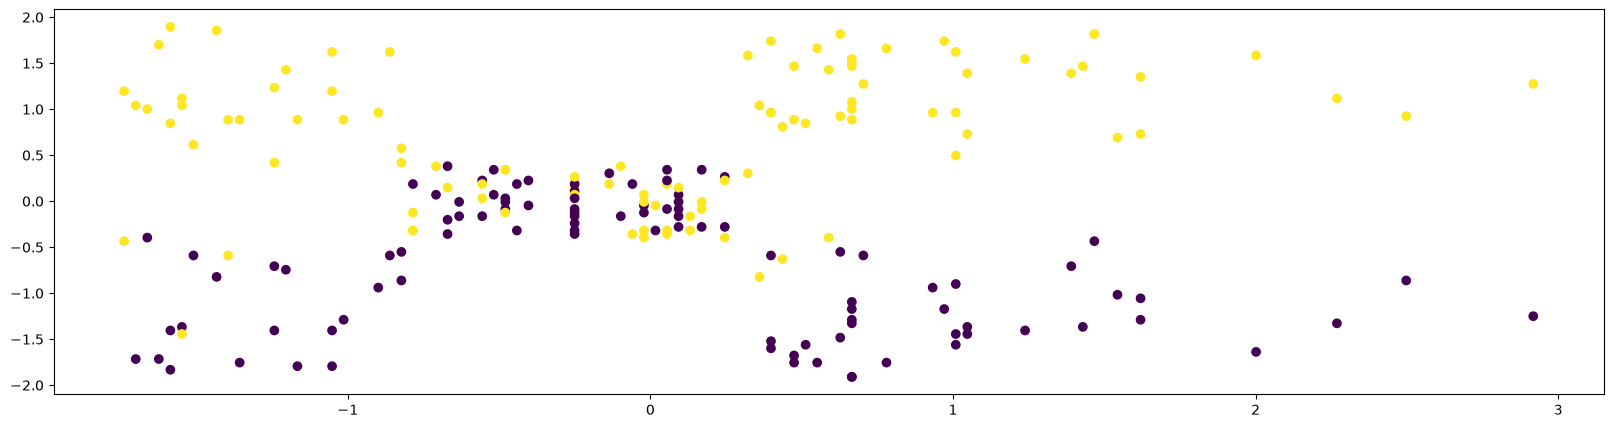

In [33]:
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pylab as plt

model = AgglomerativeClustering()
model.fit(X)
fig, axs = plt.subplots(figsize=(20, 5))
axs.scatter(
    X[:, 2],
    X[:, 3],
    c=model.labels_
)

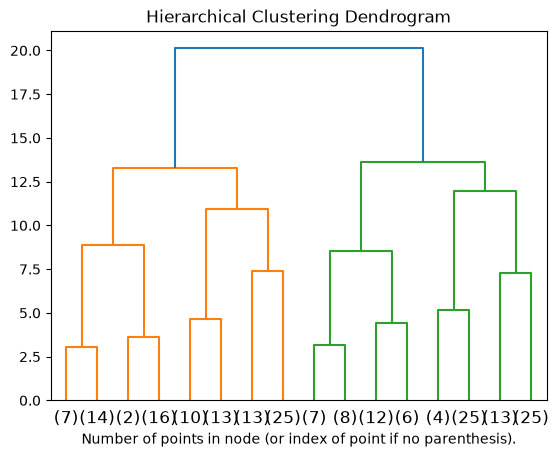

In [32]:
import numpy as np
from scipy.cluster.hierarchy import dendrogram


def plot_dendrogram(model, **kwargs):

    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1 
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    dendrogram(linkage_matrix, **kwargs)
model_2 = AgglomerativeClustering(distance_threshold=0, n_clusters=None)
model_2.fit(X)

plt.title("Hierarchical Clustering Dendrogram")
plot_dendrogram(model_2, truncate_mode="level", p=3)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.show()